# 实战Kaggle比赛：预测房价
:label:`sec_kaggle_house`

之前几节我们学习了一些训练深度网络的基本工具和网络正则化的技术（如权重衰减、暂退法等）。
本节我们将通过Kaggle比赛，将所学知识付诸实践。
Kaggle的房价预测比赛是一个很好的起点。
此数据集由Bart de Cock于2011年收集 :cite:`De-Cock.2011`，
涵盖了2006-2010年期间亚利桑那州埃姆斯市的房价。
这个数据集是相当通用的，不会需要使用复杂模型架构。
它比哈里森和鲁宾菲尔德的[波士顿房价](https://archive.ics.uci.edu/ml/machine-learning-databases/housing/housing.names)
数据集要大得多，也有更多的特征。

本节我们将详细介绍数据预处理、模型设计和超参数选择。
通过亲身实践，你将获得一手经验，这些经验将有益数据科学家的职业成长。

## 下载和缓存数据集

在整本书中，我们将下载不同的数据集，并训练和测试模型。
这里我们(**实现几个函数来方便下载数据**)。
首先，我们建立字典`DATA_HUB`，
它可以将数据集名称的字符串映射到数据集相关的二元组上，
这个二元组包含数据集的url和验证文件完整性的sha-1密钥。
所有类似的数据集都托管在地址为`DATA_URL`的站点上。


In [1]:
import hashlib
import os
import tarfile
import zipfile
import requests

#@save
DATA_HUB = dict()
DATA_URL = 'http://d2l-data.s3-accelerate.amazonaws.com/'

下面的`download`函数用来下载数据集，
将数据集缓存在本地目录（默认情况下为`../data`）中，
并返回下载文件的名称。
如果缓存目录中已经存在此数据集文件，并且其sha-1与存储在`DATA_HUB`中的相匹配，
我们将使用缓存的文件，以避免重复的下载。


In [2]:
def download(name, cache_dir=os.path.join('../pytorch', 'data')):  # @save
    """下载DATA_HUB中的文件，并返回本地文件路径"""

    # 检查文件是否存在于DATA_HUB中
    assert name in DATA_HUB, f"{name} 不存在于 {DATA_HUB}"

    url, sha1_hash = DATA_HUB[name]  # 获取下载地址和SHA-1校验值

    os.makedirs(cache_dir, exist_ok=True)  # 创建缓存目录（如果不存在）

    # 拼接文件的本地保存路径
    fname = os.path.join(cache_dir, url.split('/')[-1])

    if os.path.exists(fname):  # 如果文件已存在，检查是否完整
        sha1 = hashlib.sha1()  # 创建SHA-1哈希对象

        with open(fname, 'rb') as f:  # 以二进制模式读取文件
            while True:
                data = f.read(1048576)  # 每次读取1MB数据
                if not data:
                    break  # 文件读取完毕
                sha1.update(data)  # 更新哈希值

        if sha1.hexdigest() == sha1_hash:
            return fname  # 校验通过，直接使用缓存文件

    # 文件不存在或校验失败时重新下载
    print(f'正在从{url}下载{fname}...')

    r = requests.get(url, stream=True, verify=True)  # 发送HTTPS下载请求

    with open(fname, 'wb') as f:
        f.write(r.content)  # 将下载内容写入本地文件

    return fname  # 返回文件保存路径

我们还需实现两个实用函数：
一个将下载并解压缩一个zip或tar文件，
另一个是将本书中使用的所有数据集从`DATA_HUB`下载到缓存目录中。


In [3]:
def download_extract(name, folder=None):  # @save
    """下载并解压ZIP/TAR文件"""

    fname = download(name)  # 下载文件，获取本地路径
    base_dir = os.path.dirname(fname)  # 获取文件所在目录
    data_dir, ext = os.path.splitext(fname)  # 分离文件路径和扩展名

    if ext == '.zip':
        fp = zipfile.ZipFile(fname, 'r')  # 打开ZIP压缩文件
    elif ext in ('.tar', '.gz'):
        fp = tarfile.open(fname, 'r')  # 打开TAR/GZ压缩文件
    else:
        assert False, '只有zip/tar文件可以被解压缩'

    fp.extractall(base_dir)  # 将文件解压到指定目录

    # 返回指定子目录或默认数据目录
    return os.path.join(base_dir, folder) if folder else data_dir

## Kaggle

[Kaggle](https://www.kaggle.com)是一个当今流行举办机器学习比赛的平台，
每场比赛都以至少一个数据集为中心。
许多比赛有赞助方，他们为获胜的解决方案提供奖金。
该平台帮助用户通过论坛和共享代码进行互动，促进协作和竞争。
虽然排行榜的追逐往往令人失去理智：
有些研究人员短视地专注于预处理步骤，而不是考虑基础性问题。
但一个客观的平台有巨大的价值：该平台促进了竞争方法之间的直接定量比较，以及代码共享。
这便于每个人都可以学习哪些方法起作用，哪些没有起作用。
如果我们想参加Kaggle比赛，首先需要注册一个账户（见 :numref:`fig_kaggle`）。

![Kaggle网站](../img/kaggle.png)
:width:`400px`
:label:`fig_kaggle`

在房价预测比赛页面（如 :numref:`fig_house_pricing` 所示）的"Data"选项卡下可以找到数据集。我们可以通过下面的网址提交预测，并查看排名：

>https://www.kaggle.com/c/house-prices-advanced-regression-techniques

![房价预测比赛页面](../img/house-pricing.png)
:width:`400px`
:label:`fig_house_pricing`

## 访问和读取数据集

注意，竞赛数据分为训练集和测试集。
每条记录都包括房屋的属性值和属性，如街道类型、施工年份、屋顶类型、地下室状况等。
这些特征由各种数据类型组成。
例如，建筑年份由整数表示，屋顶类型由离散类别表示，其他特征由浮点数表示。
这就是现实让事情变得复杂的地方：例如，一些数据完全丢失了，缺失值被简单地标记为“NA”。
每套房子的价格只出现在训练集中（毕竟这是一场比赛）。
我们将希望划分训练集以创建验证集，但是在将预测结果上传到Kaggle之后，
我们只能在官方测试集中评估我们的模型。
在 :numref:`fig_house_pricing` 中，"Data"选项卡有下载数据的链接。

开始之前，我们将[**使用`pandas`读入并处理数据**]，
这是我们在 :numref:`sec_pandas`中引入的。
因此，在继续操作之前，我们需要确保已安装`pandas`。
幸运的是，如果我们正在用Jupyter阅读该书，可以在不离开笔记本的情况下安装`pandas`。


In [7]:
# 如果没有安装pandas，可取消注释进行安装
# !pip install pandas

%matplotlib inline  
# 在Jupyter Notebook中直接显示图像

import numpy as np  # 数值计算库，用于数组和矩阵运算
import pandas as pd  # 数据分析库，用于读取和处理表格数据
import torch  # PyTorch深度学习框架，支持张量计算和自动求导
from torch import nn  # 神经网络模块，用于构建网络层和损失函数
from d2l import torch as d2l  # 动手学深度学习工具包，提供辅助函数

为方便起见，我们可以使用上面定义的脚本下载并缓存Kaggle房屋数据集。


In [8]:
# 注册Kaggle房价预测比赛的训练数据集
DATA_HUB['kaggle_house_train'] = (  # @save
    DATA_URL + 'kaggle_house_pred_train.csv',  # 训练集下载地址
    '585e9cc93e70b39160e7921475f9bcd7d31219ce'  # SHA-1校验值
)

# 注册Kaggle房价预测比赛的测试数据集
DATA_HUB['kaggle_house_test'] = (  # @save
    DATA_URL + 'kaggle_house_pred_test.csv',  # 测试集下载地址
    'fa19780a7b011d9b009e8bff8e99922a8ee2eb90'  # SHA-1校验值
)

我们使用`pandas`分别加载包含训练数据和测试数据的两个CSV文件。


In [9]:
# 下载并读取Kaggle房价预测训练集，转换为Pandas DataFrame
train_data = pd.read_csv(download('kaggle_house_train'))

# 下载并读取Kaggle房价预测测试集，转换为Pandas DataFrame
test_data = pd.read_csv(download('kaggle_house_test'))

正在从http://d2l-data.s3-accelerate.amazonaws.com/kaggle_house_pred_train.csv下载../pytorch/data/kaggle_house_pred_train.csv...
正在从http://d2l-data.s3-accelerate.amazonaws.com/kaggle_house_pred_test.csv下载../pytorch/data/kaggle_house_pred_test.csv...


训练数据集包括1460个样本，每个样本80个特征和1个标签，
而测试数据集包含1459个样本，每个样本80个特征。


In [10]:
print(train_data.shape)
print(test_data.shape)

(1460, 81)
(1459, 80)


让我们看看[**前四个和最后两个特征，以及相应标签**]（房价）。


In [11]:
print(train_data.iloc[0:4, [0, 1, 2, 3, -3, -2, -1]])

   Id  MSSubClass MSZoning  LotFrontage SaleType SaleCondition  SalePrice
0   1          60       RL         65.0       WD        Normal     208500
1   2          20       RL         80.0       WD        Normal     181500
2   3          60       RL         68.0       WD        Normal     223500
3   4          70       RL         60.0       WD       Abnorml     140000


我们可以看到，(**在每个样本中，第一个特征是ID，**)
这有助于模型识别每个训练样本。
虽然这很方便，但它不携带任何用于预测的信息。
因此，在将数据提供给模型之前，(**我们将其从数据集中删除**)。


In [12]:
# 合并训练集和测试集的特征，便于统一进行数据预处理
all_features = pd.concat((
    train_data.iloc[:, 1:-1],  # 训练集：去掉第一列ID和最后一列房价标签
    test_data.iloc[:, 1:]      # 测试集：去掉第一列ID
))

## 数据预处理

如上所述，我们有各种各样的数据类型。
在开始建模之前，我们需要对数据进行预处理。
首先，我们[**将所有缺失的值替换为相应特征的平均值。**]然后，为了将所有特征放在一个共同的尺度上，
我们(**通过将特征重新缩放到零均值和单位方差来标准化数据**)：

$$x \leftarrow \frac{x - \mu}{\sigma},$$

其中$\mu$和$\sigma$分别表示均值和标准差。
现在，这些特征具有零均值和单位方差，即 $E[\frac{x-\mu}{\sigma}] = \frac{\mu - \mu}{\sigma} = 0$和$E[(x-\mu)^2] = (\sigma^2 + \mu^2) - 2\mu^2+\mu^2 = \sigma^2$。
直观地说，我们标准化数据有两个原因：
首先，它方便优化。
其次，因为我们不知道哪些特征是相关的，
所以我们不想让惩罚分配给一个特征的系数比分配给其他任何特征的系数更大。


In [13]:
# 如果无法获取测试集，应仅使用训练集计算均值和标准差

# 筛选所有数值型特征，排除object类型的类别特征
numeric_features = all_features.dtypes[all_features.dtypes != 'object'].index

# 对数值特征进行标准化，使均值为0、标准差为1
all_features[numeric_features] = all_features[numeric_features].apply(
    lambda x: (x - x.mean()) / x.std()
)

# 将标准化后的缺失值NaN填充为0
all_features[numeric_features] = all_features[numeric_features].fillna(0)

接下来，我们**处理离散值。**
这包括诸如“MSZoning”之类的特征。
(**我们用独热编码替换它们**)，
方法与前面将多类别标签转换为向量的方式相同
（请参见 :numref:`subsec_classification-problem`）。
例如，“MSZoning”包含值“RL”和“Rm”。
我们将创建两个新的指示器特征“MSZoning_RL”和“MSZoning_RM”，其值为0或1。
根据独热编码，如果“MSZoning”的原始值为“RL”，
则：“MSZoning_RL”为1，“MSZoning_RM”为0。
`pandas`软件包会自动为我们实现这一点。


In [16]:
# “Dummy_na=True”将“na”（缺失值）视为有效的特征值，并为其创建指示符特征
all_features = pd.get_dummies(all_features, dummy_na=True)
all_features.shape

(2919, 330)

可以看到此转换会将特征的总数量从79个增加到331个。
最后，通过`values`属性，我们可以
[**从`pandas`格式中提取NumPy格式，并将其转换为张量表示**]用于训练。


In [19]:
# 对类别特征进行独热编码，并将缺失值作为单独类别
all_features = pd.get_dummies(all_features, dummy_na=True)

# 将所有特征统一转换为float32类型
all_features = all_features.astype('float32')

# 获取训练集的样本数量
n_train = train_data.shape[0]

# 提取前n_train行特征，转换为float32类型的PyTorch张量
train_features = torch.tensor(
    all_features[:n_train].values, dtype=torch.float32
)

# 提取剩余行作为测试特征，转换为PyTorch张量
test_features = torch.tensor(
    all_features[n_train:].values, dtype=torch.float32
)

# 提取训练集的房价标签，并转换为二维列向量
train_labels = torch.tensor(
    train_data.SalePrice.values.reshape(-1, 1), dtype=torch.float32
)

# 检查数据类型
print(all_features.dtypes.value_counts())

# 检查张量形状
print(train_features.shape)
print(test_features.shape)
print(train_labels.shape)

float32    330
Name: count, dtype: int64
torch.Size([1460, 330])
torch.Size([1459, 330])
torch.Size([1460, 1])


## **训练**

首先，我们训练一个带有损失平方的线性模型。
显然线性模型很难让我们在竞赛中获胜，但线性模型提供了一种健全性检查，
以查看数据中是否存在有意义的信息。
如果我们在这里不能做得比随机猜测更好，那么我们很可能存在数据处理错误。
如果一切顺利，**线性模型将作为*基线*（baseline）模型**，
让我们直观地知道最好的模型有超出简单的模型多少。


In [20]:
# 定义均方误差损失函数（MSE）
loss = nn.MSELoss()

# 获取训练数据的特征数量
in_features = train_features.shape[1]

def get_net():
    """构建线性回归模型"""
    # 创建全连接层，将所有输入特征映射为1个房价预测值
    net = nn.Sequential(nn.Linear(in_features, 1))
    return net  # 返回模型

房价就像股票价格一样，我们关心的是相对数量，而不是绝对数量。
因此，**我们更关心相对误差$\frac{y - \hat{y}}{y}$，**
而不是绝对误差$y - \hat{y}$。
例如，如果我们在俄亥俄州农村地区估计一栋房子的价格时，
假设我们的预测偏差了10万美元，
然而那里一栋典型的房子的价值是12.5万美元，
那么模型可能做得很糟糕。
另一方面，如果我们在加州豪宅区的预测出现同样的10万美元的偏差，
（在那里，房价中位数超过400万美元）
这可能是一个不错的预测。

(**解决这个问题的一种方法是用价格预测的对数来衡量差异**)。
事实上，这也是比赛中官方用来评价提交质量的误差指标。
即将$\delta$ for $|\log y - \log \hat{y}| \leq \delta$
转换为$e^{-\delta} \leq \frac{\hat{y}}{y} \leq e^\delta$。
这使得预测价格的对数与真实标签价格的对数之间出现以下均方根误差：

$$\sqrt{\frac{1}{n}\sum_{i=1}^n\left(\log y_i -\log \hat{y}_i\right)^2}.$$


In [22]:
def log_rmse(net, features, labels):
    """计算对数均方根误差（Log RMSE）"""

    # 将预测值限制在[1, +∞)，避免对非正数取对数
    clipped_preds = torch.clamp(net(features), 1, float('inf'))

    # 对预测值和真实标签取对数，计算均方根误差
    rmse = torch.sqrt(loss(torch.log(clipped_preds),
                           torch.log(labels)))

    return rmse.item()  # 将单元素张量转换为Python数值

与前面的部分不同，**我们的训练函数将借助Adam优化器**
（我们将在后面章节更详细地描述它）。
Adam优化器的主要吸引力在于它对初始学习率不那么敏感。


In [23]:
def train(net, train_features, train_labels, test_features, test_labels,
          num_epochs, learning_rate, weight_decay, batch_size):
    """训练模型并记录训练集和测试集的损失"""

    train_ls, test_ls = [], []  # 保存每轮的训练损失和测试损失

    # 创建训练数据迭代器，按批次加载数据
    train_iter = d2l.load_array((train_features, train_labels), batch_size)

    # 使用Adam优化器，并设置学习率和权重衰减
    optimizer = torch.optim.Adam(
        net.parameters(),            # 模型的可训练参数
        lr=learning_rate,            # 学习率
        weight_decay=weight_decay    # L2正则化强度
    )

    for epoch in range(num_epochs):  # 遍历训练轮次
        net.train()  # 切换到训练模式

        for X, y in train_iter:
            optimizer.zero_grad()  # 清空梯度
            l = loss(net(X), y)    # 前向传播并计算损失
            l.backward()          # 反向传播，计算梯度
            optimizer.step()       # 更新模型参数

        net.eval()  # 切换到评估模式
        with torch.no_grad():  # 评估时不计算梯度
            # 记录当前轮次的训练损失
            train_ls.append(log_rmse(net, train_features, train_labels))

            if test_labels is not None:
                # 记录当前轮次的测试损失
                test_ls.append(log_rmse(net, test_features, test_labels))

    return train_ls, test_ls  # 返回训练和测试损失列表

## $K$折交叉验证

本书在讨论模型选择的部分（:numref:`sec_model_selection`）
中介绍了**K折交叉验证**，
它有助于模型选择和超参数调整。
我们首先需要定义一个函数，在$K$折交叉验证过程中返回第$i$折的数据。
具体地说，它选择第$i$个切片作为验证数据，其余部分作为训练数据。
注意，这并不是处理数据的最有效方法，如果我们的数据集大得多，会有其他解决办法。


In [24]:
def get_k_fold_data(k, i, X, y):
    """获取K折交叉验证的训练集和验证集"""

    assert k > 1  # 确保折数大于1
    fold_size = X.shape[0] // k  # 计算每折的样本数量

    X_train, y_train = None, None  # 初始化训练数据和标签

    for j in range(k):  # 遍历每一折
        idx = slice(j * fold_size, (j + 1) * fold_size)  # 当前折的索引范围
        X_part, y_part = X[idx, :], y[idx]  # 提取当前折的数据和标签

        if j == i:
            X_valid, y_valid = X_part, y_part  # 第i折作为验证集
        elif X_train is None:
            X_train, y_train = X_part, y_part  # 初始化训练集
        else:
            X_train = torch.cat([X_train, X_part], 0)  # 拼接训练特征
            y_train = torch.cat([y_train, y_part], 0)  # 拼接训练标签

    return X_train, y_train, X_valid, y_valid  # 返回训练集和验证集

当我们在$K$折交叉验证中训练$K$次后，**返回训练和验证误差的平均值**。


In [26]:
def k_fold(k, X_train, y_train, num_epochs, learning_rate, weight_decay,
           batch_size):
    """执行K折交叉验证，计算平均训练损失和验证损失"""

    train_l_sum, valid_l_sum = 0, 0  # 初始化训练损失和验证损失总和

    for i in range(k):  # 遍历K折交叉验证
        # 获取当前折的训练集和验证集
        data = get_k_fold_data(k, i, X_train, y_train)

        net = get_net()  # 每一折创建新的模型，重新初始化参数

        # 训练模型，获取每轮的训练损失和验证损失
        train_ls, valid_ls = train(
            net, *data, num_epochs, learning_rate, weight_decay, batch_size
        )

        train_l_sum += train_ls[-1]  # 累加最后一轮的训练损失
        valid_l_sum += valid_ls[-1]  # 累加最后一轮的验证损失

        if i == 0:
            # 绘制第一折的训练损失和验证损失曲线
            d2l.plot(
                list(range(1, num_epochs + 1)),
                [train_ls, valid_ls],
                xlabel='epoch', ylabel='rmse',
                xlim=[1, num_epochs],
                legend=['train', 'valid'],
                yscale='log'
            )

        # 输出当前折的训练损失和验证损失
        print(f'折{i + 1}，训练log rmse{float(train_ls[-1]):f}, '
              f'验证log rmse{float(valid_ls[-1]):f}')

    # 返回K折的平均训练损失和平均验证损失
    return train_l_sum / k, valid_l_sum / k

## **模型选择**

在本例中，我们选择了一组未调优的超参数，并将其留给读者来改进模型。
找到一组调优的超参数可能需要时间，这取决于一个人优化了多少变量。
有了足够大的数据集和合理设置的超参数，$K$折交叉验证往往对多次测试具有相当的稳定性。
然而，如果我们尝试了不合理的超参数，我们可能会发现验证效果不再代表真正的误差。


折1，训练log rmse0.169677, 验证log rmse0.156393
折2，训练log rmse0.162214, 验证log rmse0.190369
折3，训练log rmse0.163960, 验证log rmse0.168443
折4，训练log rmse0.167850, 验证log rmse0.154656
折5，训练log rmse0.163313, 验证log rmse0.182709
5-折验证: 平均训练log rmse: 0.165403, 平均验证log rmse: 0.170514


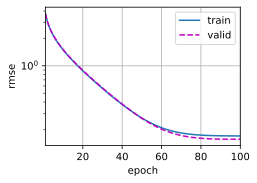

折3，训练log rmse0.163810, 验证log rmse0.168171


折4，训练log rmse0.167946, 验证log rmse0.154694


折5，训练log rmse0.163320, 验证log rmse0.182928
5-折验证: 平均训练log rmse: 0.165458, 平均验证log rmse: 0.170293


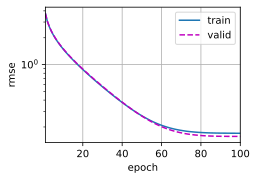

In [27]:
# 设置K折数、训练轮数、学习率、权重衰减和批量大小
k, num_epochs, lr, weight_decay, batch_size = 5, 100, 5, 0, 64

# 执行5折交叉验证，获取平均训练损失和验证损失
train_l, valid_l = k_fold(
    k, train_features, train_labels, num_epochs,
    lr, weight_decay, batch_size
)

# 输出K折交叉验证的平均Log RMSE
print(f'{k}-折验证: 平均训练log rmse: {float(train_l):f}, '
      f'平均验证log rmse: {float(valid_l):f}')

请注意，有时一组超参数的训练误差可能非常低，但$K$折交叉验证的误差要高得多，
这表明模型过拟合了。
在整个训练过程中，我们希望监控训练误差和验证误差这两个数字。
较少的过拟合可能表明现有数据可以支撑一个更强大的模型，
较大的过拟合可能意味着我们可以通过正则化技术来获益。

##  **提交Kaggle预测**

既然我们知道应该选择什么样的超参数，
我们不妨使用所有数据对其进行训练
（而不是仅使用交叉验证中使用的$1-1/K$的数据）。
然后，我们通过这种方式获得的模型可以应用于测试集。
将预测保存在CSV文件中可以简化将结果上传到Kaggle的过程。


In [28]:
def train_and_pred(train_features, test_features, train_labels, test_data,
                   num_epochs, lr, weight_decay, batch_size):
    """训练模型并生成Kaggle房价预测提交文件"""

    net = get_net()  # 创建新的线性回归模型

    # 使用全部训练数据训练模型，不设置验证集
    train_ls, _ = train(
        net, train_features, train_labels, None, None,
        num_epochs, lr, weight_decay, batch_size
    )

    # 绘制训练过程中Log RMSE的变化曲线
    d2l.plot(
        np.arange(1, num_epochs + 1),
        [train_ls],
        xlabel='epoch', ylabel='log rmse',
        xlim=[1, num_epochs], yscale='log'
    )

    # 输出最后一轮的训练误差
    print(f'训练log rmse：{float(train_ls[-1]):f}')

    # 使用训练好的模型预测测试集房价
    preds = net(test_features).detach().numpy()

    # 将预测结果添加到测试数据的SalePrice列
    test_data['SalePrice'] = pd.Series(preds.reshape(1, -1)[0])

    # 提取房屋ID和预测房价，生成提交数据
    submission = pd.concat(
        [test_data['Id'], test_data['SalePrice']], axis=1
    )

    # 导出CSV文件，不保存DataFrame索引
    submission.to_csv('submission.csv', index=False)

如果测试集上的预测与$K$倍交叉验证过程中的预测相似，
那就是时候把它们上传到Kaggle了。
下面的代码将生成一个名为`submission.csv`的文件。


训练log rmse：0.162798


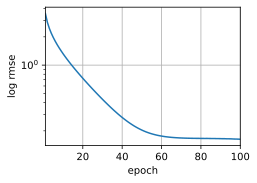

In [29]:
# 使用全部训练数据训练模型，并预测测试集房价
train_and_pred(
    train_features,  # 训练集特征
    test_features,   # 测试集特征
    train_labels,    # 训练集真实房价
    test_data,       # 测试集原始数据（包含房屋ID）
    num_epochs,      # 训练轮数
    lr,              # 学习率
    weight_decay,    # 权重衰减系数
    batch_size       # 每批次的样本数量
)

接下来，如 :numref:`fig_kaggle_submit2`中所示，
我们可以提交预测到Kaggle上，并查看在测试集上的预测与实际房价（标签）的比较情况。
步骤非常简单。

* 登录Kaggle网站，访问房价预测竞赛页面。
* 点击“Submit Predictions”或“Late Submission”按钮（在撰写本文时，该按钮位于右侧）。
* 点击页面底部虚线框中的“Upload Submission File”按钮，选择要上传的预测文件。
* 点击页面底部的“Make Submission”按钮，即可查看结果。

![向Kaggle提交数据](../img/kaggle-submit2.png)
:width:`400px`
:label:`fig_kaggle_submit2`

## 小结

* 真实数据通常混合了不同的数据类型，需要进行预处理。
* 常用的预处理方法：将实值数据重新缩放为零均值和单位方法；用均值替换缺失值。
* 将类别特征转化为指标特征，可以使我们把这个特征当作一个独热向量来对待。
* 我们可以使用$K$折交叉验证来选择模型并调整超参数。
* 对数对于相对误差很有用。